## ResNet Evaluation (1)

Evaluate ResNet trained to recognize all 22 wild bee species (network will be used for preliminary XAI experiments without humans).

In [ ]:
import sys
sys.path.append('./wingbeats/')

In [12]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix
import glob
from PIL import Image
from tensorflow.keras.layers.experimental.preprocessing import Rescaling
from sklearn.preprocessing import label_binarize # for ROC

from beexplainable.beexplainable.utils import metafile_readers as mr # an extra prefix beexplainable. may be needed
from beexplainable.beexplainable.modelling import classifiers as cls
from beexplainable.beexplainable.preprocessing import parsers as ps
from wingbeats import modelling as wm # for building simple classifiers
from wingbeats import processing as wp # for confusion matrices

In [13]:
import tensorflow as tf
print(tf.__version__)

# Select GPU
print(tf.test.gpu_device_name())

gpus = tf.config.list_physical_devices('GPU')
print("Num GPUs available:", len(gpus))
try:
    tf.config.experimental.set_memory_growth(gpus[0], True) # don't allocate whole memory
except RuntimeError as e:
    print(e) # 'Invalid device or cannot modify virtual devices once initialized.'

2.8.1
/device:GPU:0
Num GPUs available: 1


2023-08-17 18:52:19.106133: I tensorflow/core/common_runtime/gpu/gpu_device.cc:1525] Created device /device:GPU:0 with 46962 MB memory:  -> device: 0, name: Quadro RTX 8000, pci bus id: 0000:65:00.0, compute capability: 7.5


In [14]:
use_mini_dataset   = True # load test set
compress_B_lucorum = True # compress the 4 difficult species together
bees_subfolder = '22_species/' if compress_B_lucorum else '25_species/'

dataset_folder = 'Bees_Christian/' if use_mini_dataset else 'Bees/'
metafolder = './beexplainable/metafiles/'

BEES_PATH = '../data/data_lstudio/' + dataset_folder
PROTOTYPE_PATH = '../data/Wildbienen/Prototypes/'
IMAGES_PATH = metafolder + dataset_folder + 'images.txt'
IMAGES_LABELS_PATH = metafolder + dataset_folder + bees_subfolder + 'image_class_labels.txt'
CLASSES_PATH = metafolder + dataset_folder + bees_subfolder + 'classes.txt'

W_H_PATH = metafolder + dataset_folder + 'widths_heights.txt'
BBOX_PATH = metafolder + dataset_folder + 'bounding_boxes.txt'
PART_CONTOURS = metafolder + dataset_folder + 'part_contours.npy'

MODELS_PATH  = './beexplainable/models/'
FIGURES_PATH = './beexplainable/figures/'

## Load images

In [15]:
batch_size = 16 if use_mini_dataset else 64
img_height = img_width = 224
crop_to_bbox = False # whether to crop image to bbox
overlay_mask = False # whether to segment object and hide background

In [16]:
# Read file IDs and corresponding class labels
img_dict = mr.metafile_to_dict(IMAGES_PATH)
img_label_dict = mr.metafile_to_dict(IMAGES_LABELS_PATH)
file_ids = list( img_dict.keys() )
y_true   = list( img_label_dict.values() )
y_true   = np.asarray(y_true, dtype = np.uint8) - 1
# Note! Labels in CUB format start at index 1, but cross entropy needs to start at 0

# Read class names
cls_dict = mr.metafile_to_dict(CLASSES_PATH)
classes = list( cls_dict.values() )

In [17]:
# Add extension to path if extra input transformation is enabled
input_form = 'raw'
if crop_to_bbox and not overlay_mask:
    BEES_PATH = BEES_PATH[:-1] + '_bbox/'
    input_form = 'bbox'
elif not crop_to_bbox and overlay_mask:
    BEES_PATH = BEES_PATH[:-1] + '_masked/Whole/'
    input_form = 'mask'
elif crop_to_bbox and overlay_mask:
    BEES_PATH = BEES_PATH[:-1] + '_masked_bbox/Whole/'
    input_form = 'mask_bbox'
print(BEES_PATH)

../data/data_lstudio/Bees_Christian/


In [18]:
# Get dictionary of file IDs and file names
# Convert it into a tf.StaticHashTable to be able to retrieve dictionary values during eager execution
# Alternative: tf.gather
img_lookup = tf.lookup.StaticHashTable(tf.lookup.KeyValueTensorInitializer(file_ids,
                                                                           list(img_dict.values())),
                                       default_value = 'No file')

# Parsing function for tf.Dataset
parse_image_lab = lambda file_id, label: (ps.parse_image(file_id, img_lookup, img_width, img_height, BEES_PATH),
                                          label)

In [19]:
# Conversion to tf.Dataset
test_set = ps.parse_to_dataset(file_ids, y_true, parse_image_lab)
test_set = test_set.cache().batch(batch_size).prefetch(tf.data.experimental.AUTOTUNE)

# Normalize raw images
normalization_layer = Rescaling(1./255)
test_set = test_set.map(lambda x, y: (normalization_layer(x), y))

2023-08-17 18:52:20.570832: W tensorflow/core/kernels/data/cache_dataset_ops.cc:768] The calling iterator did not fully read the dataset being cached. In order to avoid unexpected truncation of the dataset, the partially cached contents of the dataset  will be discarded. This can happen if you have an input pipeline similar to `dataset.cache().take(k).repeat()`. You should use `dataset.take(k).cache().repeat()` instead.


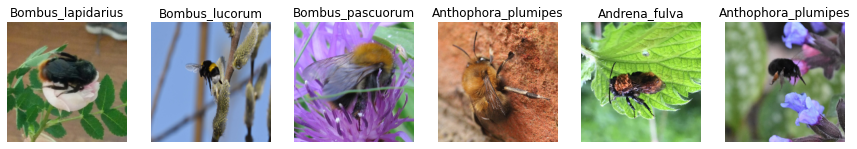

In [20]:
# Plot a few examples
plt.figure(figsize = (15, 10))
num_cols = min(6, batch_size)
with tf.device('/CPU:0'):
    for images, labels in test_set.take(1):
        for i in range(num_cols):
            plt.subplot(1, num_cols, i + 1)
            plt.imshow(images[i])
            plt.title(cls_dict[str(labels[i].numpy()+1)])
            plt.axis("off")
plt.show()

In [ ]:
for image_batch, labels_batch in test_set.take(1):
    print(image_batch.shape)
    print(labels_batch[0])

## Validation on Test Set

In [21]:
# Define model parameters
in_shape = (img_width, img_height, 3)
drop_rate, lr, reg = 0.5, 1e-3, 1e-3 # lr and reg optimized in HPO notebook

constructor, out_shape =  wm.build_simple_classifier, len(classes)

loss = 'sparse_categorical_crossentropy'
metrics = ['accuracy', tf.keras.metrics.SparseTopKCategoricalAccuracy(k=3, name='top_3_accuracy')]

# Define whether to load fine grained backbone weights
load_pretrained_backbone = True # if False, ImageNet weights are loaded
# ResNet50 weights trained on iNat2021
# https://github.com/visipedia/newt/tree/main/benchmark
pretrained_weights_file = MODELS_PATH + 'backbones/resnet50_simclr_v1_inat20_no_top_500.h5' if load_pretrained_backbone else None

# Derive model name
dataset_type = 'all' # model was trained on whole dataset and is now tested on mini dataset
init = 'iNat' if load_pretrained_backbone else 'Imagenet'
model_name = 'ResNet50_' + init + '_raw' # model was trained on raw whole dataset
weights_file = MODELS_PATH + dataset_type + '/' + bees_subfolder + model_name + '/' + model_name + '.h5' # path to load weights from
print('Model loaded from ' + weights_file)

# The pretrained ResNet on iNat already has a GlobalAvgPooling layer
add_global_avg = False if load_pretrained_backbone else True

# Whether to retrain the backbone or not
trainable = True

Model loaded from ./beexplainable/models/all/22_species/ResNet50_iNat_raw/ResNet50_iNat_raw.h5


In [ ]:
# Build and compile
tf.keras.backend.clear_session()
cnn_name = 'CNN_Blocks_' + model_name

cnn = cls.CNN_ResNet50(in_shape, drop_rate, add_global_avg = add_global_avg, trainable = trainable,
                       weights_file = pretrained_weights_file, name = cnn_name)

model = constructor(in_shape, out_shape, cnn, reg,
                    input_name = 'jpg', model_name = model_name)

model.load_weights(weights_file)

model.compile(tf.keras.optimizers.Adam(lr), loss = loss, metrics = metrics)

In [24]:
# Test accuracy
model.evaluate(test_set, verbose = 1)

46/46 [==============================] - 1s 26ms/step - loss: 29.2408 - accuracy: 0.7631 - top_3_accuracy: 0.9490


[29.24078941345215, 0.7630854249000549, 0.9490358233451843]

### Confusion matrix

In [12]:
# Build the confusion matrix
pred_specs = np.argmax(model.predict(test_set, verbose = 1), axis = 1)
conf_mat = np.round( confusion_matrix(y_true, pred_specs, normalize = 'true'), 2 )

46/46 [==============================] - 7s 110ms/step


In [18]:
# Sort classes alphabetically
sorted_cls = sorted(list(cls_dict.values()))

# Get cls indexes of the sorted classes
sorted_ids = np.argsort(list(cls_dict.values()))

In [19]:
# Permute rows and columns in conf. mat. so that species are sorted
conf_mat = conf_mat[sorted_ids, :]
conf_mat = conf_mat[:, sorted_ids]

In [20]:
# Sort files of prototypes
proto_files = sorted( glob.glob(PROTOTYPE_PATH + '*.jpg') )
proto_files.remove(PROTOTYPE_PATH + 'Bombus_cryptarum_41698591_1.jpg')
proto_files.remove(PROTOTYPE_PATH + 'Bombus_magnus_39079115_1.jpg')
proto_files.remove(PROTOTYPE_PATH + 'Bombus_terrestris_50780653_1.jpg')

In [21]:
# Derive species names
species = [ pf[pf.rfind('/') + 1:] for pf in proto_files]
species = [ s.split('_')[0] + ' ' + s.split('_')[1] for s in species]

In [22]:
# Read and resize prototype images
proto_imgs = [Image.open(pf).resize((img_width, img_height)) for pf in proto_files]

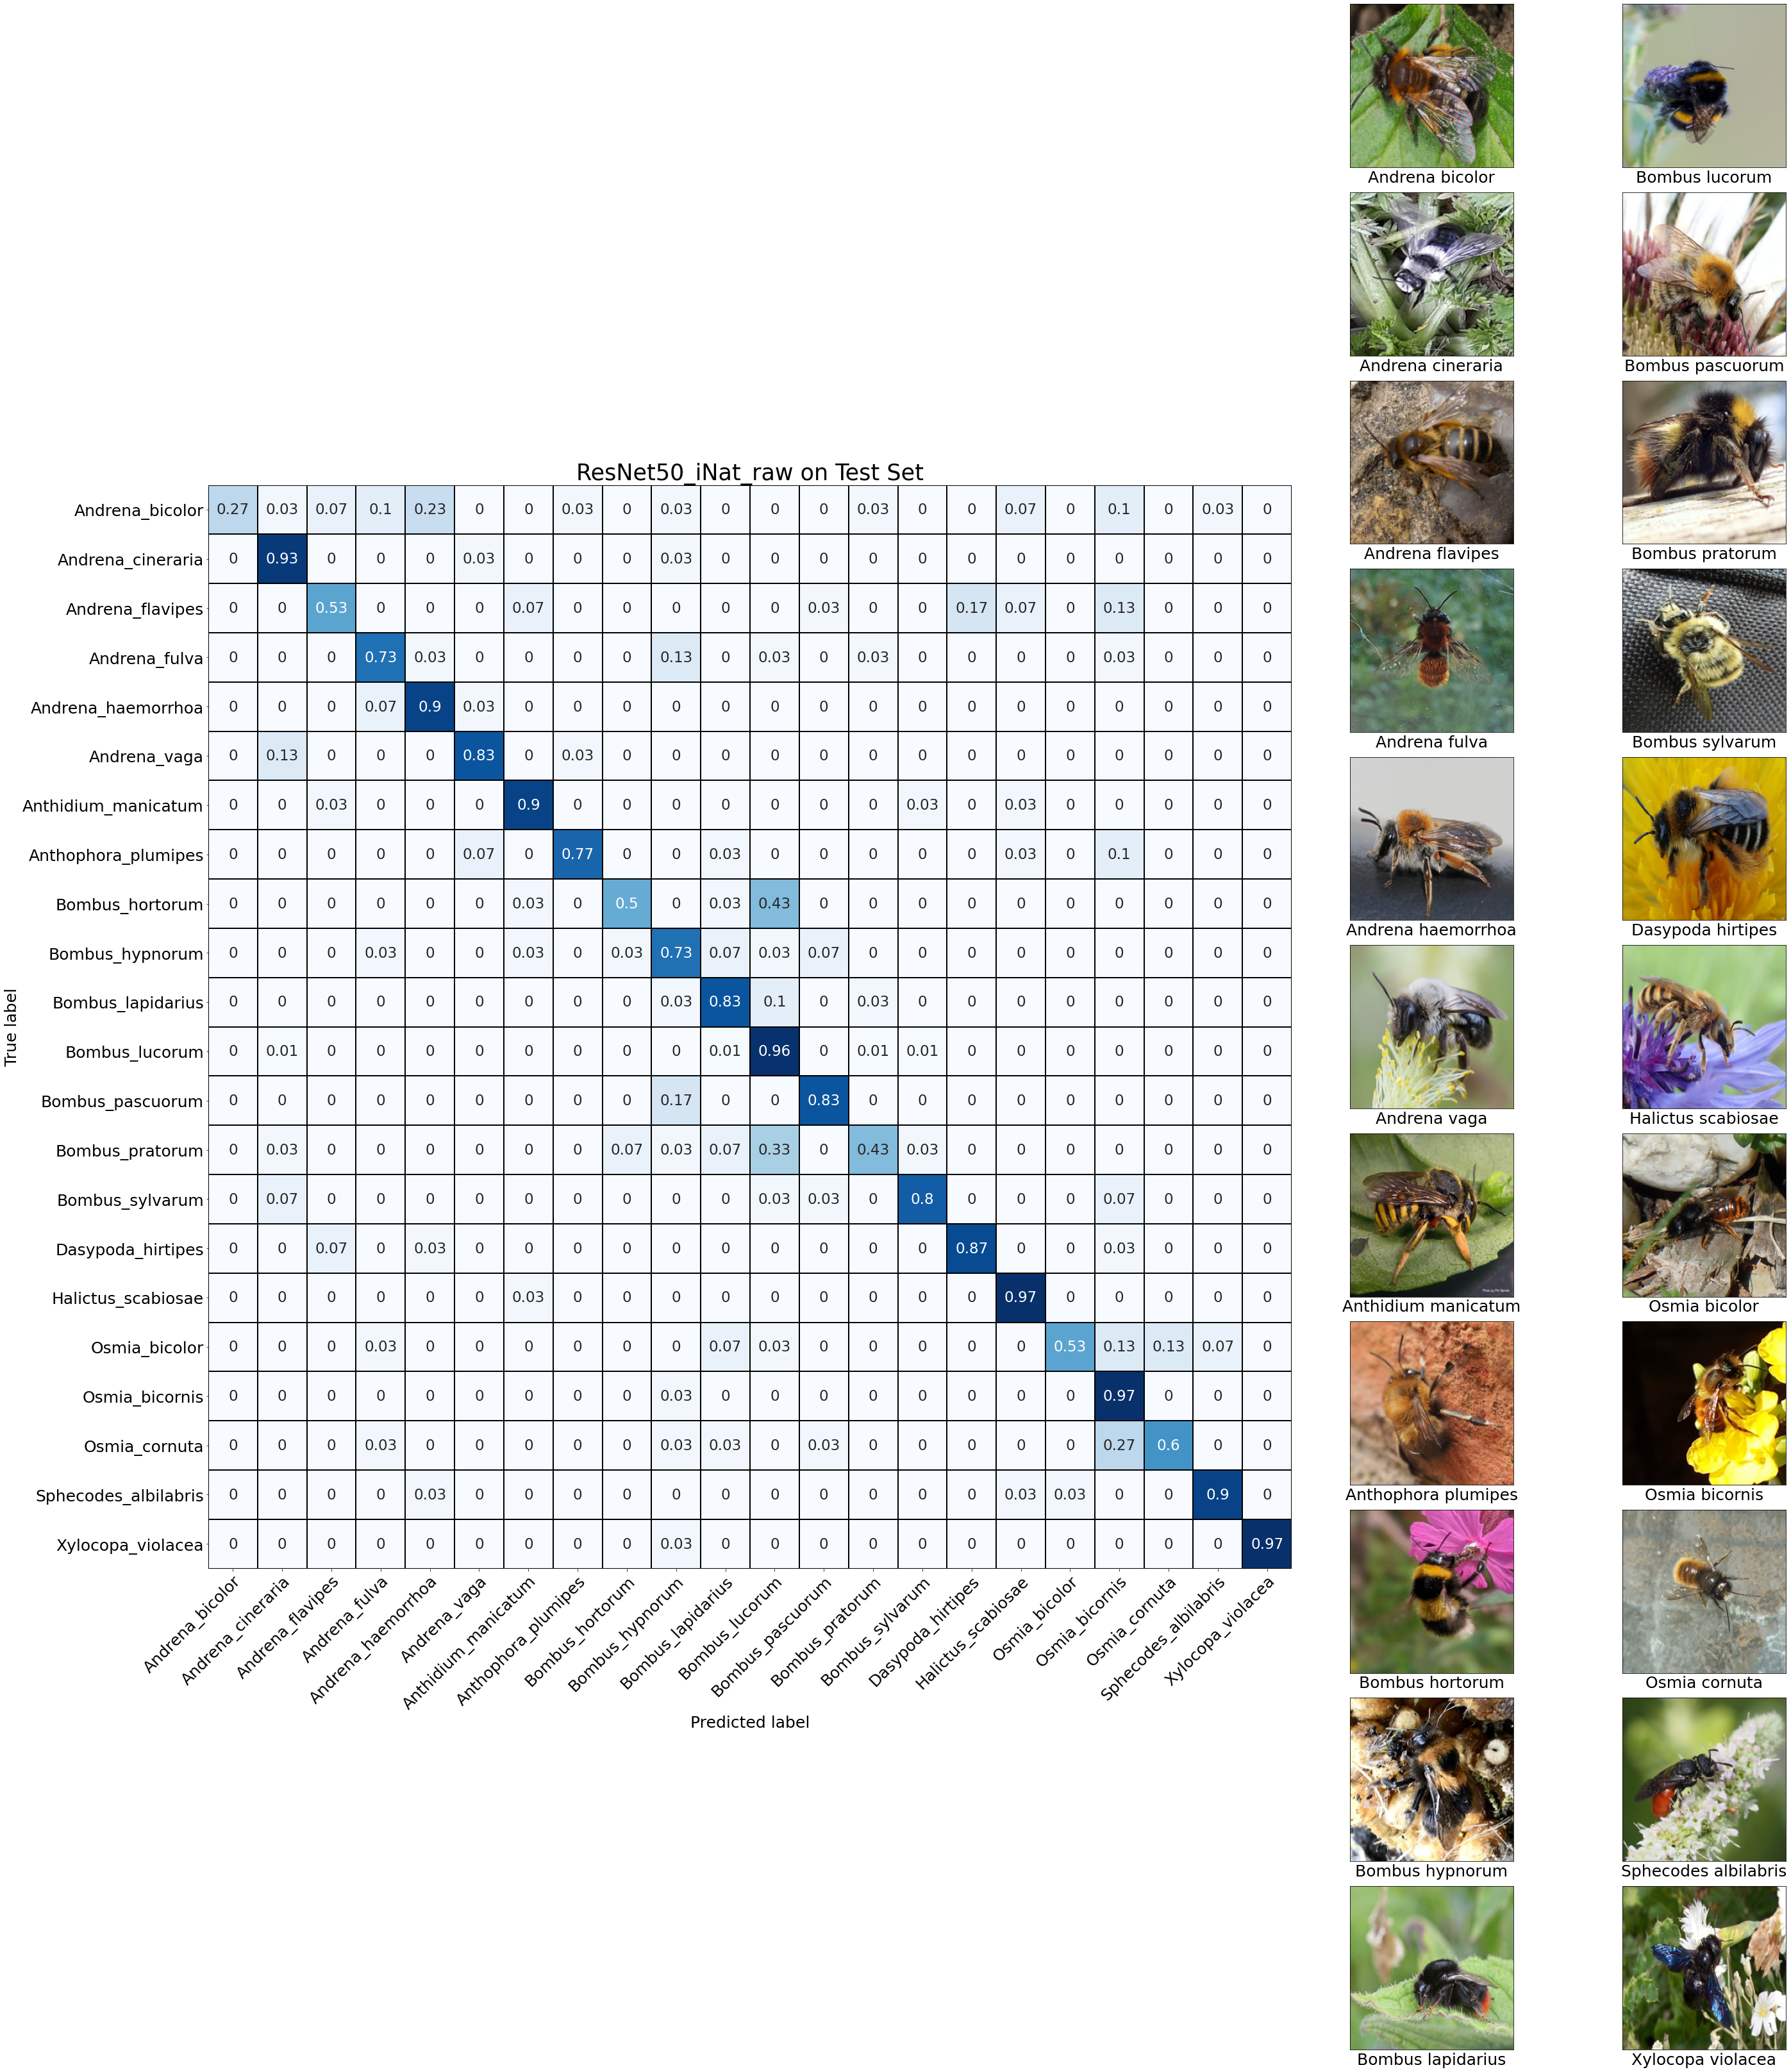

In [23]:
# Plot conf. mat. along with prototypes
num_cls = len(classes)
num_rows, num_cols = num_cls//2, 6
plt.figure(figsize=(40,45))
plt.subplot2grid((num_rows, num_cols), (0, 0), rowspan = num_rows, colspan = num_cols - 2)
wp.plot_heatmap(conf_mat, xticklab = sorted_cls, yticklab = sorted_cls,
                xlab = 'Predicted label', ylab = 'True label', title = 'ResNet50_iNat_raw on Test Set',
                path_to_save = None, title_size = 35, ticks_size = 25, label_size = 25, item_size = 23)

for i in range(num_cls):
    if i < num_cls//2:
        plt.subplot2grid((num_rows, num_cols), (i, num_cols - 2))
    else:
        plt.subplot2grid((num_rows, num_cols), (i-num_cls//2, num_cols - 1))
    plt.imshow(proto_imgs[i])
    plt.xticks([], [])
    plt.yticks([], [])
    plt.xlabel(species[i], fontsize = 25)

plt.savefig(FIGURES_PATH + 'conf_mat/' + model_name + '.png', bbox_inches='tight')
plt.tight_layout()
plt.show()

### AUC Curves

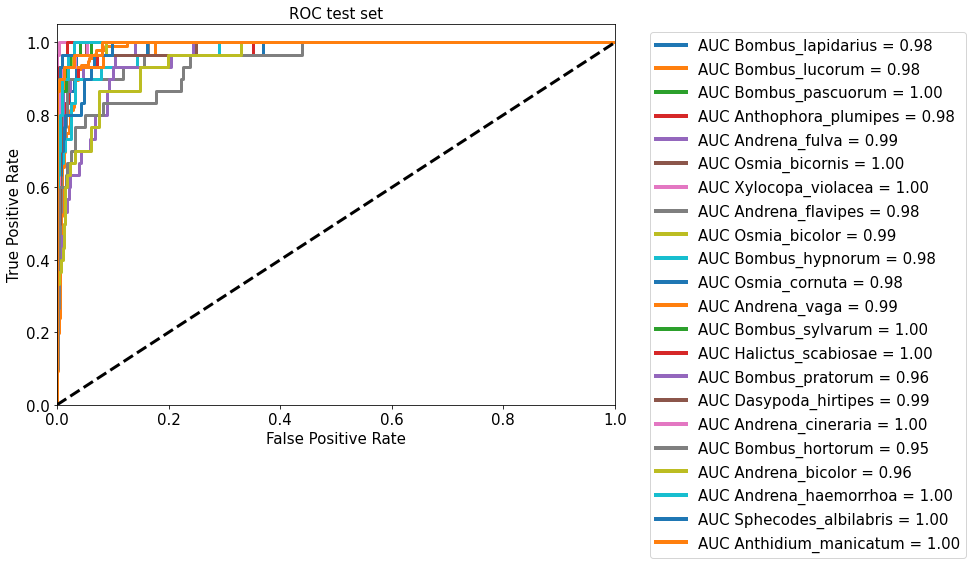

In [24]:
# Label vector needs to be binarized in order to build ROC
y_true_bin = label_binarize(y_true, classes = range(len(classes)))
y_pred = model.predict(test_set)

# ROC + AUC
fig = plt.figure(figsize = (10, 7))
wp.plot_roc(y_true_bin, y_pred, classes, 'ROC test set')#, title_size, ticks_size, label_size)
plt.savefig(FIGURES_PATH + 'roc_auc/' + model_name + '.png', bbox_inches='tight')
plt.show()

### Worst Predictions

In [13]:
# Worst predictions = the false predictions with the highest probability output
# Get indexes of all wrong predictions
ind_wrong_preds = np.where(pred_specs != y_true)[0]

# Get probabilities of the wrong predictions
wrong_probs = np.max(y_pred[ind_wrong_preds], axis = -1)

# Get indexes within wrong preds. of top 12 worst predictions
wrong_ind = np.argsort(wrong_probs)[-12 : ]

# Get top 12 worst probs
worst_probs = wrong_probs[wrong_ind]

# Get indexes in the test set of the worst predictions
worst_pred_ids = np.asarray(file_ids)[ np.asarray(ind_wrong_preds)[wrong_ind] ]
worst_pred_true_labs = np.asarray(y_true)[ np.asarray(ind_wrong_preds)[wrong_ind] ]

# Read and resize the most difficult images
worst_imgs = [Image.open(BEES_PATH + img_dict[wpi]).resize((img_width, img_height)) for wpi in worst_pred_ids]

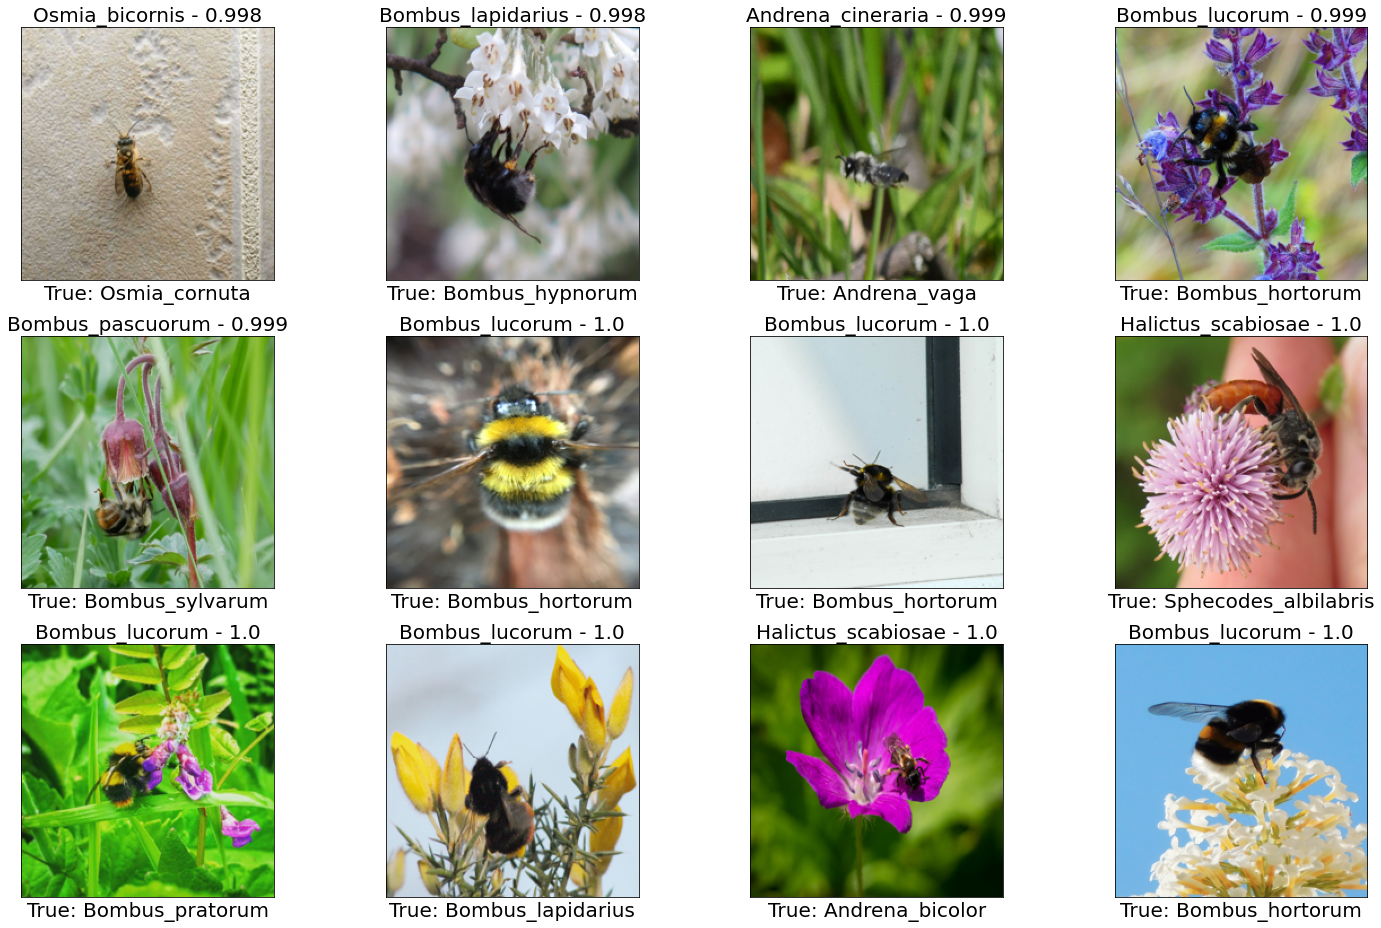

In [15]:
# Plot worst predictions
num_rows, num_cols = 3, 4
title_size = 20
fig = plt.figure(figsize = (21, 4 * num_rows + 1))

for i in range(len(worst_pred_ids)):
    plt.subplot(num_rows, num_cols, i+1)
    plt.imshow(worst_imgs[i])
    true_cls = classes[ worst_pred_true_labs[i] ]
    pred_cls = classes[ pred_specs[ int(worst_pred_ids[i])-1 ] ]
    certainty = np.round(wrong_probs[wrong_ind[i]], 3)
    plt.title(pred_cls + ' - ' + str(certainty), fontsize = title_size)
    plt.xlabel('True: ' + true_cls, fontsize = title_size)
    plt.xticks([])
    plt.yticks([])
plt.tight_layout()
fig.savefig(FIGURES_PATH + 'worst_preds/' + model_name + '.png', bbox_inches = 'tight')
plt.show()